<a href="https://colab.research.google.com/github/Saniya-Nawaz/Plant_disease_detection_cnn/blob/main/Copy_of_Plant_Disease_Detection_Using_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Plant Disease Detection Using CNN

**Objective:** To classify plant leaf images as healthy or diseased using a Convolutional Neural Network (CNN).

# New section

In [ ]:
# Step 1: Import the required libraries

import os
import random
import shutil
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.model_selection import train_test_split

print("Project environment initialized successfully!")
print("NumPy version:", np.__version__)
print("All required libraries imported successfully.")

Project environment initialized successfully!
NumPy version: 2.1.3
All required libraries imported successfully.


In [ ]:
!pip -q install kaggle

from google.colab import files
uploaded = files.upload()

Saving dataset_summary.csv to dataset_summary (2).csv


In [ ]:
import os

os.makedirs("/content/plant_dataset", exist_ok=True)
os.makedirs("/root/.kaggle", exist_ok=True)

!cp /content/kaggle.json /root/.kaggle/kaggle.json
!chmod 600 /root/.kaggle/kaggle.json

!kaggle datasets download \
    -d emmarex/plantdisease \
    -p /content/plant_dataset \
    --unzip

cp: cannot stat '/content/kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/emmarex/plantdisease
License(s): unknown
100% 658M/658M [00:05<00:00, 118MB/s]



In [ ]:
from pathlib import Path

DATA_DIR = Path("/content/plant_dataset")

for item in DATA_DIR.iterdir():
    print(item.name)

PlantVillage
plantvillage


In [ ]:
from pathlib import Path

DATA_DIR = Path("/content/plant_dataset")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

class_folders = []

for folder in DATA_DIR.rglob("*"):
    if folder.is_dir():
        image_count = sum(
            1 for file in folder.iterdir()
            if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS
        )

        if image_count > 0:
            class_folders.append((folder, image_count))

print("Number of image-containing folders:", len(class_folders))
print("\nImages in each folder:\n")

for folder, count in sorted(class_folders):
    print(f"{folder.name}: {count} images")

Number of image-containing folders: 30

Images in each folder:

Pepper__bell___Bacterial_spot: 997 images
Pepper__bell___healthy: 1478 images
Potato___Early_blight: 1000 images
Potato___Late_blight: 1000 images
Potato___healthy: 152 images
Tomato_Bacterial_spot: 2127 images
Tomato_Early_blight: 1000 images
Tomato_Late_blight: 1909 images
Tomato_Leaf_Mold: 952 images
Tomato_Septoria_leaf_spot: 1771 images
Tomato_Spider_mites_Two_spotted_spider_mite: 1676 images
Tomato__Target_Spot: 1404 images
Tomato__Tomato_YellowLeaf__Curl_Virus: 3208 images
Tomato__Tomato_mosaic_virus: 373 images
Tomato_healthy: 1591 images
Pepper__bell___Bacterial_spot: 997 images
Pepper__bell___healthy: 1478 images
Potato___Early_blight: 1000 images
Potato___Late_blight: 1000 images
Potato___healthy: 152 images
Tomato_Bacterial_spot: 2127 images
Tomato_Early_blight: 1000 images
Tomato_Late_blight: 1909 images
Tomato_Leaf_Mold: 952 images
Tomato_Septoria_leaf_spot: 1771 images
Tomato_Spider_mites_Two_spotted_spider_

In [ ]:
from pathlib import Path

DATA_DIR = Path("/content/plant_dataset")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

for folder in DATA_DIR.rglob("*"):
    if folder.is_dir():
        count = sum(
            1 for file in folder.iterdir()
            if file.is_file()
            and file.suffix.lower() in IMAGE_EXTENSIONS
        )

        if count > 0:
            print(f"{folder}  -->  {count} images")

/content/plant_dataset/PlantVillage/Potato___Early_blight  -->  1000 images
/content/plant_dataset/PlantVillage/Pepper__bell___healthy  -->  1478 images
/content/plant_dataset/PlantVillage/Tomato_Spider_mites_Two_spotted_spider_mite  -->  1676 images
/content/plant_dataset/PlantVillage/Tomato__Target_Spot  -->  1404 images
/content/plant_dataset/PlantVillage/Tomato_Late_blight  -->  1909 images
/content/plant_dataset/PlantVillage/Tomato_Septoria_leaf_spot  -->  1771 images
/content/plant_dataset/PlantVillage/Tomato_Bacterial_spot  -->  2127 images
/content/plant_dataset/PlantVillage/Tomato_Leaf_Mold  -->  952 images
/content/plant_dataset/PlantVillage/Tomato_healthy  -->  1591 images
/content/plant_dataset/PlantVillage/Pepper__bell___Bacterial_spot  -->  997 images
/content/plant_dataset/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus  -->  3208 images
/content/plant_dataset/PlantVillage/Tomato_Early_blight  -->  1000 images
/content/plant_dataset/PlantVillage/Potato___Late_blight  

In [ ]:
from pathlib import Path
from sklearn.model_selection import train_test_split
import shutil

# Original dataset: use only ONE copy
SOURCE_DIR = Path("/content/plant_dataset/PlantVillage")

# Folder to store the split dataset
OUTPUT_DIR = Path("/content/Plant_Disease_Split")

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

# Check the source directory
if not SOURCE_DIR.is_dir():
    raise FileNotFoundError(f"Dataset not found: {SOURCE_DIR}")

# Get all plant disease classes
class_dirs = sorted(
    folder for folder in SOURCE_DIR.iterdir()
    if folder.is_dir()
)

print("Number of classes:", len(class_dirs))

# Reset the output folder if rerunning this cell
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

# Create train, validation, and test folders
for split in ["train", "validation", "test"]:
    (OUTPUT_DIR / split).mkdir(parents=True, exist_ok=True)

# Split each disease class separately
for class_dir in class_dirs:
    images = sorted(
        file for file in class_dir.iterdir()
        if file.is_file()
        and file.suffix.lower() in IMAGE_EXTENSIONS
    )

    # 70% training, 30% remaining
    train_images, remaining_images = train_test_split(
        images,
        test_size=0.30,
        random_state=42
    )

    # Divide the remaining images equally
    val_images, test_images = train_test_split(
        remaining_images,
        test_size=0.50,
        random_state=42
    )

    split_data = {
        "train": train_images,
        "validation": val_images,
        "test": test_images
    }

    for split_name, files_list in split_data.items():
        destination = OUTPUT_DIR / split_name / class_dir.name
        destination.mkdir(parents=True, exist_ok=True)

        for image_file in files_list:
            shutil.copy2(
                image_file,
                destination / image_file.name
            )

print("\nDataset splitting completed!")

# Display the number of images in each split
for split in ["train", "validation", "test"]:
    total = sum(
        1 for file in (OUTPUT_DIR / split).rglob("*")
        if file.is_file()
        and file.suffix.lower() in IMAGE_EXTENSIONS
    )
    print(f"{split.capitalize()} images: {total}")

print("\nDataset saved at:", OUTPUT_DIR)

Number of classes: 15

Dataset splitting completed!
Train images: 14440
Validation images: 3097
Test images: 3101

Dataset saved at: /content/Plant_Disease_Split


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Path to the split dataset
OUTPUT_DIR = Path("/content/Plant_Disease_Split")

# Check whether the dataset split exists
if not OUTPUT_DIR.exists():
    raise FileNotFoundError(
        "Dataset split not found. Run Step 5 first."
    )

# Image settings
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Load training images
train_raw = tf.keras.utils.image_dataset_from_directory(
    str(OUTPUT_DIR / "train"),
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=42
)

# Load validation images
val_raw = tf.keras.utils.image_dataset_from_directory(
    str(OUTPUT_DIR / "validation"),
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# Load testing images
test_raw = tf.keras.utils.image_dataset_from_directory(
    str(OUTPUT_DIR / "test"),
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# Check that all splits use the same class mapping
class_names = train_raw.class_names

assert val_raw.class_names == class_names
assert test_raw.class_names == class_names

# Normalize pixel values from 0-255 to 0-1
rescaling_layer = tf.keras.layers.Rescaling(1.0 / 255)

train_ds = train_raw.map(
    lambda images, labels: (rescaling_layer(images), labels),
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

val_ds = val_raw.map(
    lambda images, labels: (rescaling_layer(images), labels),
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

test_ds = test_raw.map(
    lambda images, labels: (rescaling_layer(images), labels),
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

print("\nPreprocessing completed successfully!")
print("Number of disease classes:", len(class_names))
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Classes:", class_names)

# Verify image dimensions and normalized pixel values
images, labels = next(iter(train_ds))

print("\nBatch shape:", images.shape)
print("Minimum pixel value:", float(tf.reduce_min(images)))
print("Maximum pixel value:", float(tf.reduce_max(images)))

Found 14440 files belonging to 15 classes.
Found 3097 files belonging to 15 classes.
Found 3101 files belonging to 15 classes.

Preprocessing completed successfully!
Number of disease classes: 15
Image size: (128, 128)
Batch size: 32
Classes: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']

Batch shape: (32, 128, 128, 3)
Minimum pixel value: 0.0
Maximum pixel value: 0.9421569108963013


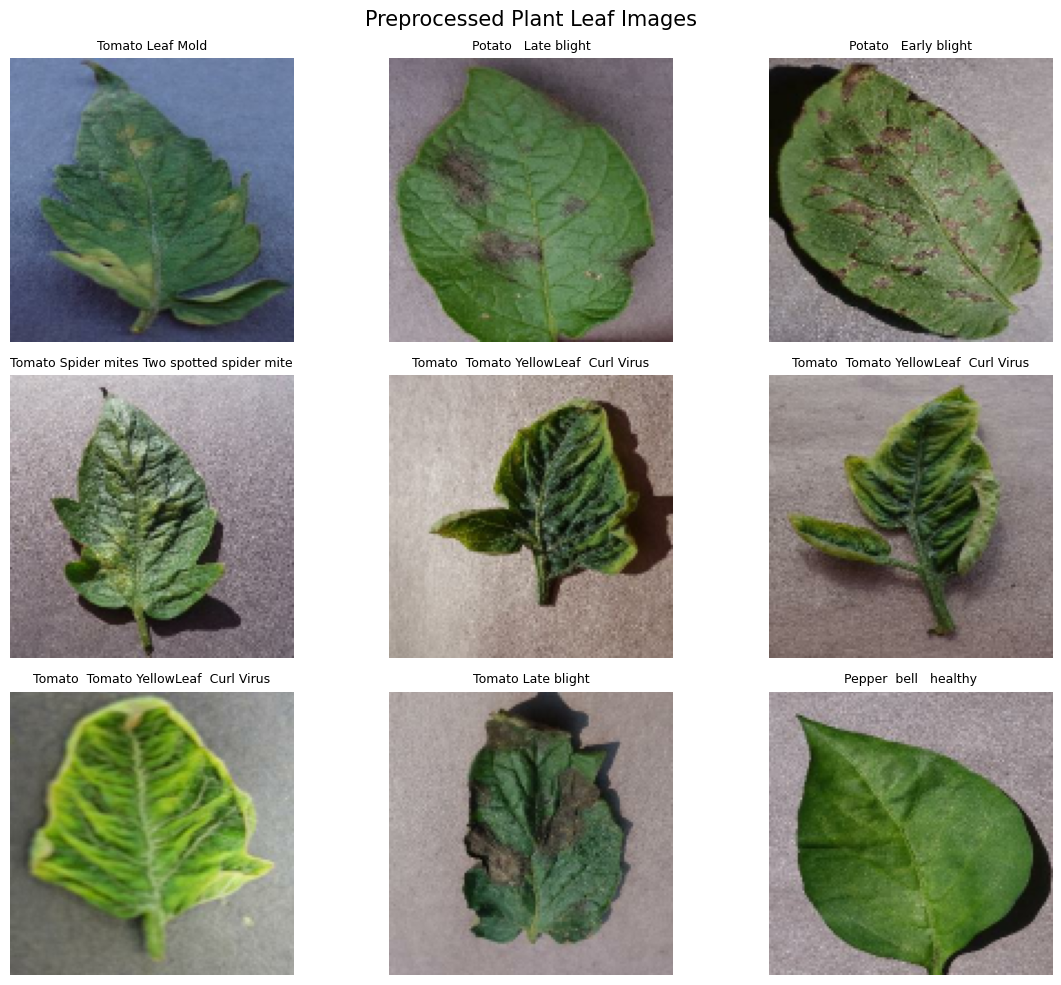

In [ ]:
# Step 7: Visualize preprocessed leaf images

import matplotlib.pyplot as plt

# Get a batch of preprocessed training images
images, labels = next(iter(train_ds))

# Display 9 images
plt.figure(figsize=(12, 10))

for i in range(9):
    plt.subplot(3, 3, i + 1)

    # Images are already normalized to [0, 1]
    plt.imshow(images[i].numpy())

    # Convert numeric label to class name
    label_index = int(labels[i].numpy())
    class_name = class_names[label_index]

    plt.title(class_name.replace("_", " "), fontsize=9)
    plt.axis("off")

plt.suptitle("Preprocessed Plant Leaf Images", fontsize=15)
plt.tight_layout()
plt.show()

In [ ]:
# Step 8: Dataset summary

from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path("/content/Plant_Disease_Split")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

splits = ["train", "validation", "test"]
class_names = sorted(
    folder.name
    for folder in (OUTPUT_DIR / "train").iterdir()
    if folder.is_dir()
)

summary = []

for class_name in class_names:
    row = {"Disease Class": class_name}

    for split in splits:
        class_dir = OUTPUT_DIR / split / class_name

        count = sum(
            1 for file in class_dir.iterdir()
            if file.is_file()
            and file.suffix.lower() in IMAGE_EXTENSIONS
        )

        row[split.capitalize()] = count

    row["Total"] = sum(row[split.capitalize()] for split in splits)
    summary.append(row)

df = pd.DataFrame(summary)

print("DATASET SUMMARY BY CLASS")
display(df)

print("\nTOTAL IMAGES IN EACH SPLIT")
print("Training:", df["Train"].sum())
print("Validation:", df["Validation"].sum())
print("Testing:", df["Test"].sum())
print("Total images:", df["Total"].sum())
print("Total classes:", len(df))

# Save the summary for the project report
df.to_csv("/content/dataset_summary.csv", index=False)

print("\nDataset summary saved successfully!")

DATASET SUMMARY BY CLASS


,Disease Class,Train,Validation,Test,Total
0,Pepper__bell___Bacterial_spot,697,150,150,997
1,Pepper__bell___healthy,1034,222,222,1478
2,Potato___Early_blight,700,150,150,1000
3,Potato___Late_blight,700,150,150,1000
4,Potato___healthy,106,23,23,152
5,Tomato_Bacterial_spot,1488,319,320,2127
6,Tomato_Early_blight,700,150,150,1000
7,Tomato_Late_blight,1336,286,287,1909
8,Tomato_Leaf_Mold,666,143,143,952
9,Tomato_Septoria_leaf_spot,1239,266,266,1771



TOTAL IMAGES IN EACH SPLIT
Training: 14440
Validation: 3097
Testing: 3101
Total images: 20638
Total classes: 15

Dataset summary saved successfully!


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
from pathlib import Path
import shutil
import pandas as pd

# Prepared dataset location
SOURCE_DIR = Path("/content/Plant_Disease_Split")

# Google Drive destination
DRIVE_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_CNN_Project"
)
DRIVE_DIR.mkdir(parents=True, exist_ok=True)

# Verify the dataset exists
if not SOURCE_DIR.exists():
    raise FileNotFoundError(
        "Prepared dataset not found. Please check Step 5."
    )

# Count images in every class and split
image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}
rows = []

for class_dir in sorted((SOURCE_DIR / "train").iterdir()):
    if not class_dir.is_dir():
        continue

    row = {"Disease Class": class_dir.name}

    for split in ["train", "validation", "test"]:
        folder = SOURCE_DIR / split / class_dir.name

        count = sum(
            1 for f in folder.iterdir()
            if f.is_file() and f.suffix.lower() in image_extensions
        )

        row[split.capitalize()] = count

    row["Total"] = row["Train"] + row["Validation"] + row["Test"]
    rows.append(row)

df = pd.DataFrame(rows)

# Save dataset summary
df.to_csv(DRIVE_DIR / "dataset_summary.csv", index=False)

# Create ZIP file for sharing
zip_path = shutil.make_archive(
    str(DRIVE_DIR / "Plant_Disease_Split"),
    "zip",
    root_dir=str(SOURCE_DIR)
)

print("Dataset saved successfully!")
print("Total images:", int(df["Total"].sum()))
print("Number of classes:", len(df))
print("Dataset ZIP:", zip_path)
print("Summary CSV:", DRIVE_DIR / "dataset_summary.csv")

Dataset saved successfully!
Total images: 20638
Number of classes: 15
Dataset ZIP: /content/drive/MyDrive/Plant_Disease_CNN_Project/Plant_Disease_Split.zip
Summary CSV: /content/drive/MyDrive/Plant_Disease_CNN_Project/dataset_summary.csv


In [ ]:
from pathlib import Path

DRIVE_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_CNN_Project"
)

report = f"""
PLANT DISEASE DETECTION USING CNN
Dataset Preparation Report

Dataset: PlantVillage
Total images: {int(df['Total'].sum())}
Number of classes: {len(df)}

Training images: {int(df['Train'].sum())}
Validation images: {int(df['Validation'].sum())}
Testing images: {int(df['Test'].sum())}

Image size during loading: 128 x 128 pixels
Color format: RGB
Normalization: Pixel values divided by 255
Dataset split: 70% training, 15% validation, 15% testing
Data augmentation: Not applied

The images are organized into train, validation,
and test folders, with separate folders for each class.

Note: Resizing and normalization are applied by the
TensorFlow preprocessing pipeline when images are loaded.
The original image files in the ZIP are not modified.
"""

(DRIVE_DIR / "dataset_summary.txt").write_text(
    report.strip(),
    encoding="utf-8"
)

print("Dataset information file saved successfully!")

Dataset information file saved successfully!


Step 1: Verify the datasets and class mapping

In [ ]:

# PERSON 2: CNN MODEL DEVELOPMENT
# Step 1: Verify prepared data from Person 1

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import json

# Reuse Person 1's existing variables
assert "train_ds" in globals(), "Run Person 1's preprocessing cells first."
assert "val_ds" in globals(), "Validation dataset is missing."
assert "test_ds" in globals(), "Test dataset is missing."
assert "class_names" in globals(), "Class names are missing."

NUM_CLASSES = len(class_names)
IMG_HEIGHT, IMG_WIDTH = 128, 128

print("Number of classes:", NUM_CLASSES)
print("Classes:", class_names)
print("Image dimensions:", IMG_HEIGHT, "x", IMG_WIDTH)

images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel range:",
      float(tf.reduce_min(images)),
      "to",
      float(tf.reduce_max(images)))

assert images.shape[1:] == (128, 128, 3)
assert NUM_CLASSES > 1

print("Prepared data verification completed!")


Number of classes: 15
Classes: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']
Image dimensions: 128 x 128
Image batch shape: (32, 128, 128, 3)
Label batch shape: (32,)
Pixel range: 0.0 to 0.9686275124549866
Prepared data verification completed!


Step 2: Build the CNN architecture

In [ ]:

# Step 2: Create the CNN model

from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # First convolution block
    layers.Conv2D(32, (3, 3), padding="same",
                  activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), padding="same",
                  activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), padding="same",
                  activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification block
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,695 (436.31 KB)

 Trainable params: 111,695 (436.31 KB)

 Non-trainable params: 0 (0.00 B)

Step 3: Compile the model

In [ ]:

# Step 3: Compile the CNN

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN compiled successfully!")


CNN compiled successfully!


Step 4: Train the model

In [ ]:

# Step 4: Configure callbacks and train the CNN

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# Save outputs to Google Drive if it is mounted;
# otherwise, save them in the Colab runtime.
drive_path = Path("/content/drive/MyDrive")

if drive_path.exists():
    OUTPUT_DIR = drive_path / "Plant_Disease_CNN_Project"
else:
    OUTPUT_DIR = Path("/content/Plant_Disease_CNN_Project")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

best_model_path = OUTPUT_DIR / "best_plant_disease_cnn.keras"

callbacks = [
    ModelCheckpoint(
        filepath=str(best_model_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)

print("CNN training completed!")


Epoch 1/20
452/452 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.2160 - loss: 2.3899
Epoch 1: val_loss improved from None to 1.92772, saving model to /content/drive/MyDrive/Plant_Disease_CNN_Project/best_plant_disease_cnn.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Plant_Disease_CNN_Project/best_plant_disease_cnn.keras
452/452 ━━━━━━━━━━━━━━━━━━━━ 549s 1s/step - accuracy: 0.2772 - loss: 2.2019 - val_accuracy: 0.3620 - val_loss: 1.9277 - learning_rate: 0.0010
Epoch 2/20
452/452 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4629 - loss: 1.6229
Epoch 2: val_loss improved from 1.92772 to 1.28888, saving model to /content/drive/MyDrive/Plant_Disease_CNN_Project/best_plant_disease_cnn.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Plant_Disease_CNN_Project/best_plant_disease_cnn.keras
452/452 ━━━━━━━━━━━━━━━━━━━━ 546s 1s/step - accuracy: 0.5072 - loss: 1.4897 - val_accuracy: 0.5802 - val_loss: 1.2889 - learning_rate: 0.0010
Epoch 3/20
452/452 ━━━━━━━━━━━━

Step 5: Plot accuracy and loss

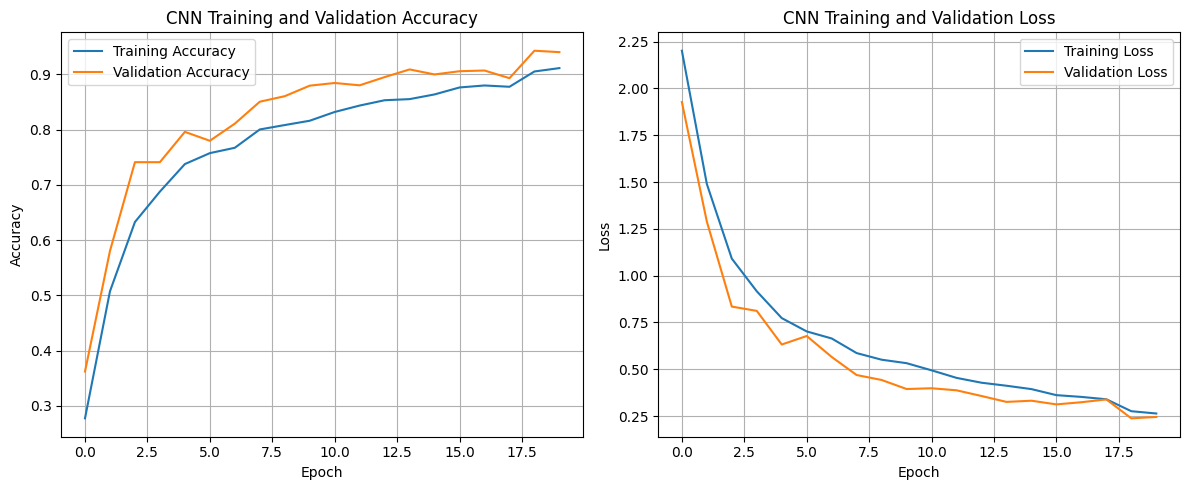

In [ ]:

# Step 5: Visualize training performance

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"],
         label="Training Accuracy")
plt.plot(history.history["val_accuracy"],
         label="Validation Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"],
         label="Training Loss")
plt.plot(history.history["val_loss"],
         label="Validation Loss")
plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


Step 6: Save the trained model and class names

In [ ]:
from google.colab import drive
from pathlib import Path
import json

# Mount Google Drive at a new location
drive.mount('/content/gdrive')

# Create the project folder
OUTPUT_DIR = Path(
    "/content/gdrive/MyDrive/Plant_Disease_CNN_Project"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save the trained model
model_path = OUTPUT_DIR / "plant_disease_cnn.keras"
model.save(str(model_path))

# Save class names
class_names_path = OUTPUT_DIR / "class_names.json"

with open(class_names_path, "w", encoding="utf-8") as f:
    json.dump(list(class_names), f, indent=4)

# Verify saved files
print("Model saved:", model_path.exists())
print("Class names saved:", class_names_path.exists())
print("Files:", list(OUTPUT_DIR.iterdir()))

Mounted at /content/gdrive
Model saved: True
Class names saved: True
Files: [PosixPath('/content/gdrive/MyDrive/Plant_Disease_CNN_Project/plant_disease_cnn.keras'), PosixPath('/content/gdrive/MyDrive/Plant_Disease_CNN_Project/class_names.json')]


**MODEL TESTING & EVALUATION**

Load the trained model and prepare test data

In [ ]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import json
import zipfile
import pandas as pd

from pathlib import Path
from google.colab import drive
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Mount Google Drive at the location used in your saving code
if not Path("/content/gdrive/MyDrive").exists():
    drive.mount("/content/gdrive")

# Project folder in Google Drive
PROJECT_DIR = Path(
    "/content/gdrive/MyDrive/Plant_Disease_CNN_Project"
)

MODEL_PATH = PROJECT_DIR / "plant_disease_cnn.keras"
CLASS_PATH = PROJECT_DIR / "class_names.json"

# Support the original /content/drive mount if that is where
# your files were saved
if not MODEL_PATH.exists():
    alternate_dir = Path(
        "/content/drive/MyDrive/Plant_Disease_CNN_Project"
    )

    if (alternate_dir / "plant_disease_cnn.keras").exists():
        PROJECT_DIR = alternate_dir
        MODEL_PATH = PROJECT_DIR / "plant_disease_cnn.keras"
        CLASS_PATH = PROJECT_DIR / "class_names.json"

# Check that the required files exist
if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Trained model not found: {MODEL_PATH}. "
        "Check that Person 2 saved and shared the model correctly."
    )

if not CLASS_PATH.exists():
    raise FileNotFoundError(
        f"Class names file not found: {CLASS_PATH}"
    )

# Load the trained CNN
evaluation_model = tf.keras.models.load_model(
    str(MODEL_PATH)
)

# Load the exact class names used by Person 2
with open(CLASS_PATH, "r", encoding="utf-8") as f:
    saved_class_names = json.load(f)

print("Trained CNN loaded successfully!")
print("Number of classes:", len(saved_class_names))
print("Model input shape:", evaluation_model.input_shape)
print("Model output shape:", evaluation_model.output_shape)

# Prepare the test dataset if it is not already available
SPLIT_DIR = Path("/content/Plant_Disease_Split")
ZIP_PATH = PROJECT_DIR / "Plant_Disease_Split.zip"

if not (SPLIT_DIR / "test").is_dir():
    if not ZIP_PATH.exists():
        raise FileNotFoundError(
            "Test dataset not found. Run Person 1's dataset "
            "preparation cells or place Plant_Disease_Split.zip "
            "in the project folder in Google Drive."
        )

    SPLIT_DIR.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(SPLIT_DIR)

    print("Dataset ZIP extracted successfully.")

# Use the existing test dataset if available.
# Otherwise, create it with the same image size and class order.
if "test_ds" not in globals():
    test_raw = tf.keras.utils.image_dataset_from_directory(
        str(SPLIT_DIR / "test"),
        image_size=(128, 128),
        batch_size=32,
        label_mode="int",
        shuffle=False,
        class_names=saved_class_names
    )

    rescaling_layer = tf.keras.layers.Rescaling(1.0 / 255)

    test_ds = test_raw.map(
        lambda images, labels: (
            rescaling_layer(images), labels
        ),
        num_parallel_calls=tf.data.AUTOTUNE
    ).prefetch(tf.data.AUTOTUNE)

elif "test_raw" in globals():
    assert list(test_raw.class_names) == list(saved_class_names), (
        "Test dataset class order does not match class_names.json. "
        "Re-create test_ds using the saved class-name order."
    )

# Use the saved class mapping for reporting
class_names = saved_class_names

assert evaluation_model.output_shape[-1] == len(class_names), (
    "Model output count does not match the number of classes."
)

print("\nTest dataset is ready!")
print("Image size: 128 x 128")
print("Normalization: Pixel values divided by 255")
print("Classes:", len(class_names))
print("Class names:", class_names)

Trained CNN loaded successfully!
Number of classes: 15
Model input shape: (None, 128, 128, 3)
Model output shape: (None, 15)

Test dataset is ready!
Image size: 128 x 128
Normalization: Pixel values divided by 255
Classes: 15
Class names: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


Evaluate accuracy, loss, confusion matrix, and classification report

97/97 ━━━━━━━━━━━━━━━━━━━━ 43s 436ms/step - accuracy: 0.9358 - loss: 0.2084

========== TEST RESULTS ==========
Test Accuracy: 93.58%
Test Loss: 0.2084
97/97 ━━━━━━━━━━━━━━━━━━━━ 40s 411ms/step

Overall Accuracy: 93.58%
Total test images: 3101
Correct predictions: 2902
Incorrect predictions: 199

========== CLASSIFICATION REPORT ==========
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot     0.9429    0.8800    0.9103       150
                     Pepper__bell___healthy     0.9690    0.9865    0.9777       222
                      Potato___Early_blight     0.9367    0.9867    0.9610       150
                       Potato___Late_blight     0.9272    0.9333    0.9302       150
                           Potato___healthy     0.9130    0.9130    0.9130        23
                      Tomato_Bacterial_spot     0.9383    0.9500    0.9441       320
                        Tomato_Early_blight     0.8654    0.90

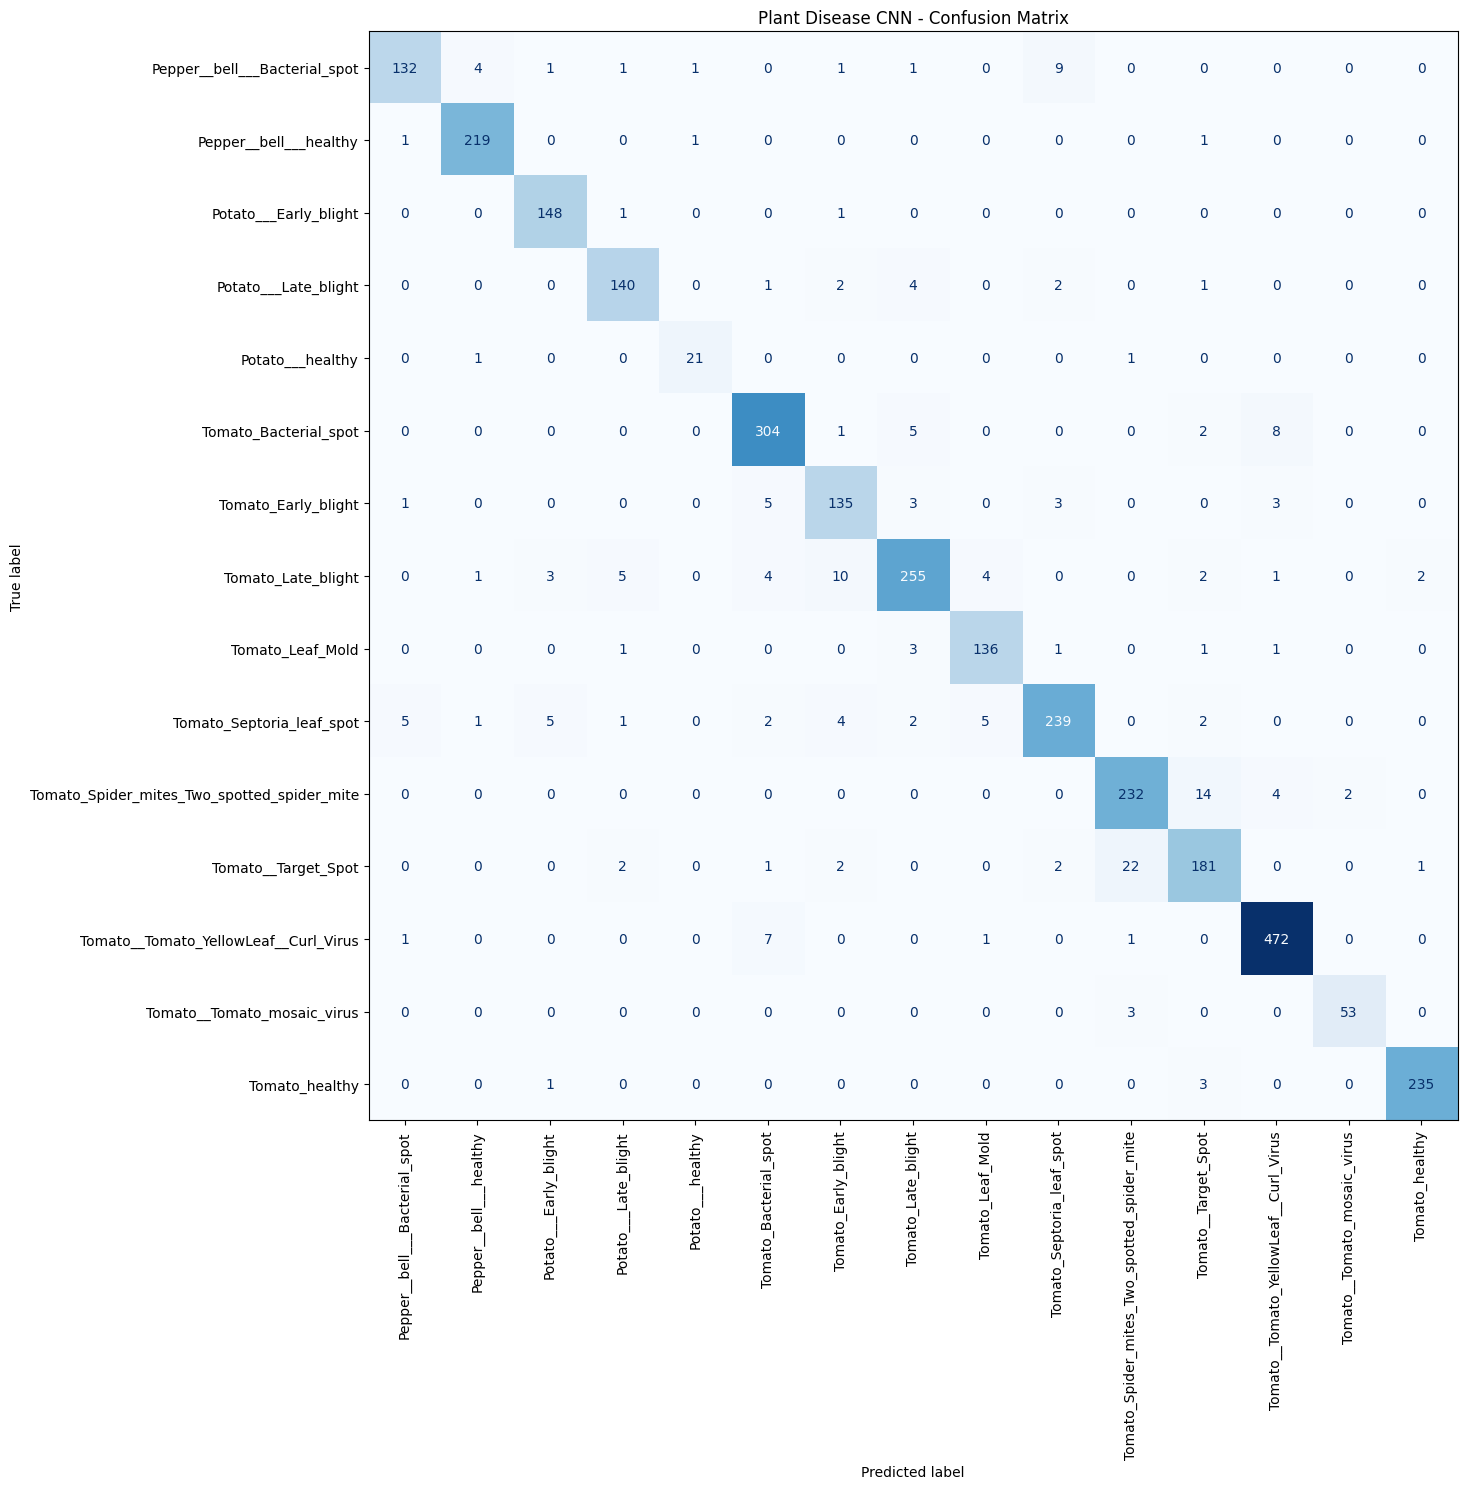


Confusion matrix saved successfully.


In [ ]:
# Step 2: Evaluate the CNN on unseen test images

# Calculate test loss and test accuracy
test_loss, test_accuracy = evaluation_model.evaluate(
    test_ds,
    verbose=1
)

print("\n========== TEST RESULTS ==========")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

# Collect actual test labels
y_true = np.concatenate([
    labels.numpy()
    for _, labels in test_ds
])

# Predict class probabilities
y_prob = evaluation_model.predict(
    test_ds,
    verbose=1
)

# Select the class with the highest output score
y_pred = np.argmax(y_prob, axis=1)

# Calculate overall accuracy independently
overall_accuracy = accuracy_score(y_true, y_pred)

print(f"\nOverall Accuracy: {overall_accuracy * 100:.2f}%")
print("Total test images:", len(y_true))
print("Correct predictions:", int(np.sum(y_true == y_pred)))
print("Incorrect predictions:", int(np.sum(y_true != y_pred)))

# Generate classification report
print("\n========== CLASSIFICATION REPORT ==========")

report_text = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(report_text)

# Create the results folder
RESULTS_DIR = PROJECT_DIR / "evaluation_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save the classification report
report_dict = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report_dict).transpose().to_csv(
    RESULTS_DIR / "classification_report.csv"
)

with open(
    RESULTS_DIR / "classification_report.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(report_text)

# Create confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

fig, ax = plt.subplots(figsize=(17, 15))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

plt.title("Plant Disease CNN - Confusion Matrix")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Save confusion matrix data
pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
).to_csv(RESULTS_DIR / "confusion_matrix.csv")

print("\nConfusion matrix saved successfully.")

Plot training accuracy and loss

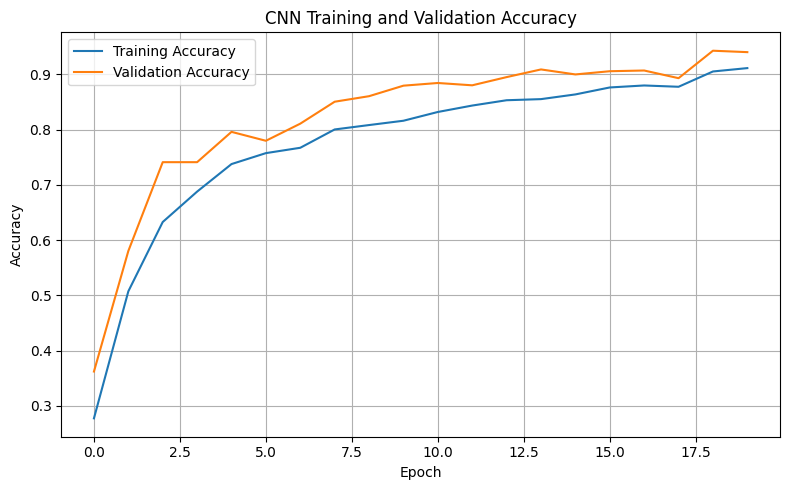

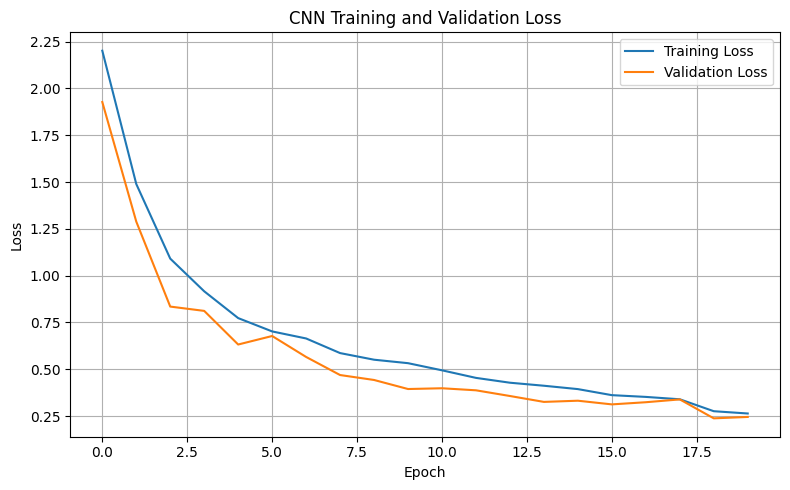

In [ ]:
# Step 3: Plot training and validation performance

if "history" in globals():
    history_data = history.history

    # Accuracy graph
    plt.figure(figsize=(8, 5))

    plt.plot(
        history_data["accuracy"],
        label="Training Accuracy"
    )
    plt.plot(
        history_data["val_accuracy"],
        label="Validation Accuracy"
    )

    plt.title("CNN Training and Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.savefig(
        RESULTS_DIR / "accuracy_graph.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()

    # Loss graph
    plt.figure(figsize=(8, 5))

    plt.plot(
        history_data["loss"],
        label="Training Loss"
    )
    plt.plot(
        history_data["val_loss"],
        label="Validation Loss"
    )

    plt.title("CNN Training and Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.savefig(
        RESULTS_DIR / "loss_graph.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()

else:
    print(
        "Training history is unavailable in this session. "
        "Use Person 2's original notebook session to generate "
        "the training and validation curves."
    )

Inspect incorrect predictions and save results

Total test images: 3101
Correct predictions: 2902
Incorrect predictions: 199


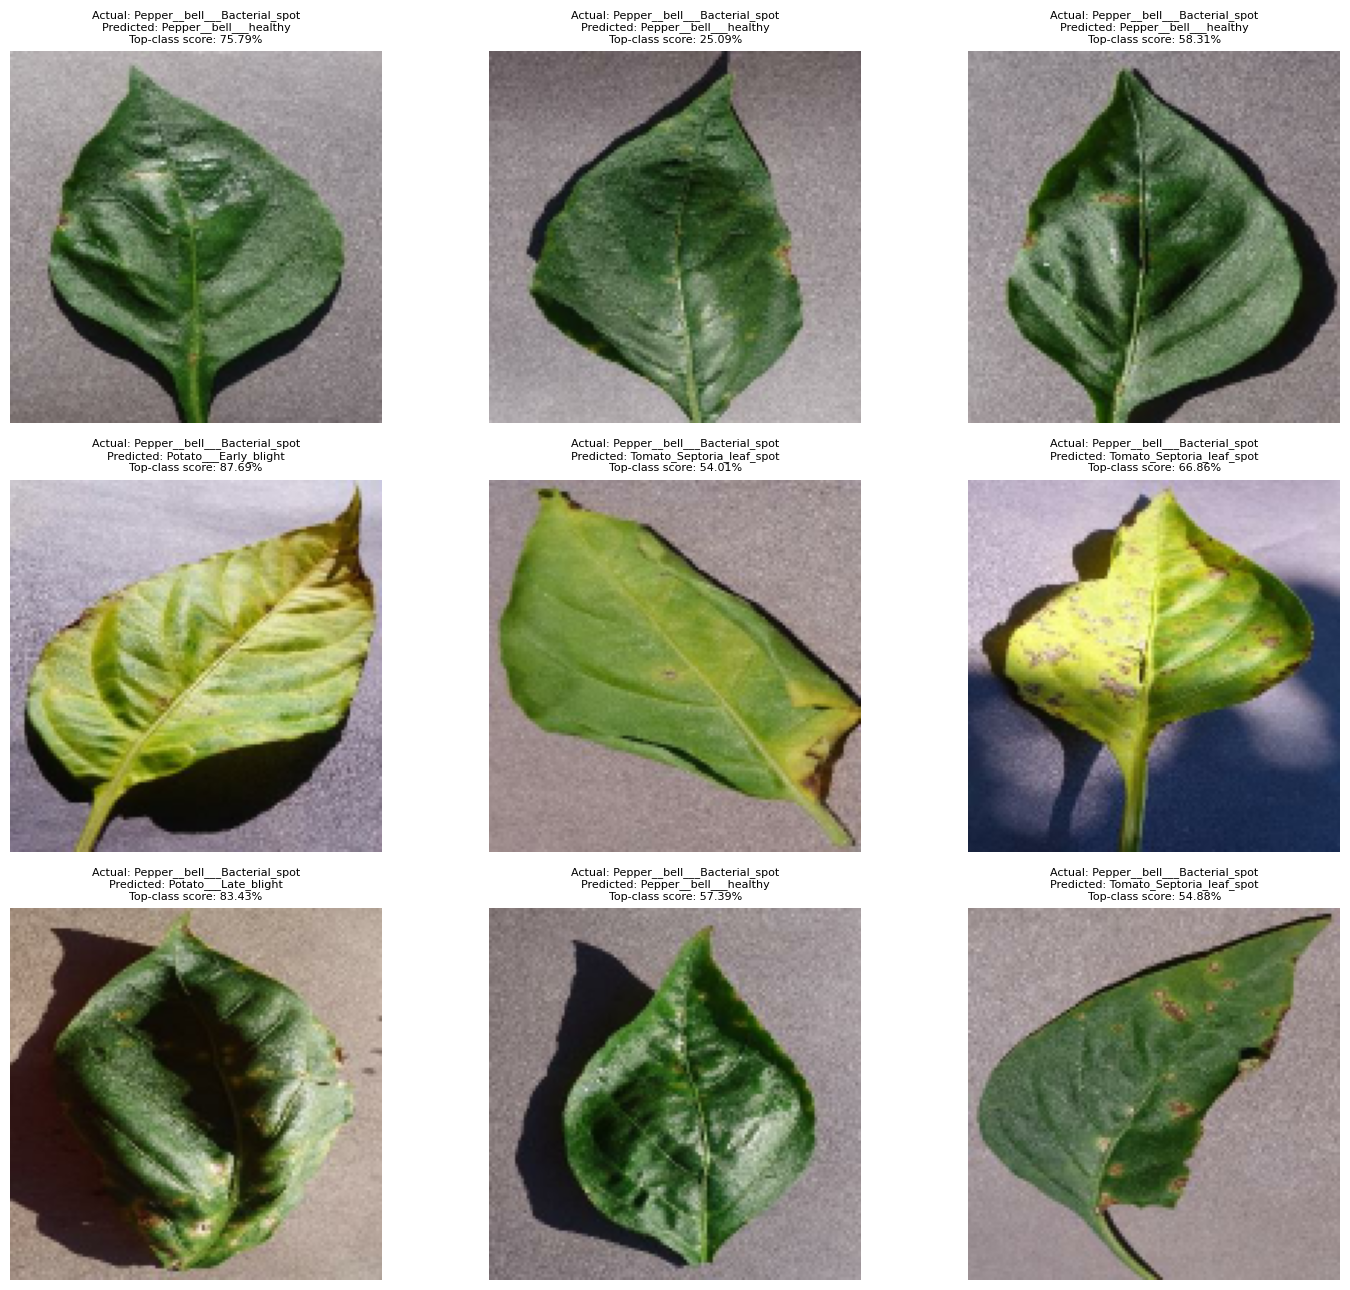


========== EVALUATION COMPLETED ==========
Results folder: /content/gdrive/MyDrive/Plant_Disease_CNN_Project/evaluation_results

Files generated:
accuracy_graph.png
classification_report.csv
classification_report.txt
confusion_matrix.csv
confusion_matrix.png
loss_graph.png
misclassified_examples.png
test_metrics.csv
test_predictions.csv


In [ ]:
# Step 4: Analyze misclassified images

misclassified = np.where(y_true != y_pred)[0]

print("Total test images:", len(y_true))
print("Correct predictions:", int(np.sum(y_true == y_pred)))
print("Incorrect predictions:", len(misclassified))

if len(misclassified) > 0:

    # Display up to 9 misclassified images
    plt.figure(figsize=(15, 13))

    BATCH_SIZE = 32
    batch_cache = {}

    for plot_idx, image_idx in enumerate(misclassified[:9]):

        batch_idx = int(image_idx // BATCH_SIZE)
        item_idx = int(image_idx % BATCH_SIZE)

        # Load only the batches needed for displaying images
        if batch_idx not in batch_cache:
            image_batch, _ = next(
                iter(test_ds.skip(batch_idx).take(1))
            )
            batch_cache[batch_idx] = image_batch.numpy()

        image = batch_cache[batch_idx][item_idx]

        actual_class = class_names[int(y_true[image_idx])]
        predicted_class = class_names[int(y_pred[image_idx])]
        score = float(np.max(y_prob[image_idx]))

        plt.subplot(3, 3, plot_idx + 1)
        plt.imshow(image)

        plt.title(
            f"Actual: {actual_class}\n"
            f"Predicted: {predicted_class}\n"
            f"Top-class score: {score:.2%}",
            fontsize=8
        )

        plt.axis("off")

    plt.tight_layout()

    plt.savefig(
        RESULTS_DIR / "misclassified_examples.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

else:
    print("No misclassified images found in the test set.")

# Step 5: Save predictions for further analysis

results_df = pd.DataFrame({
    "Actual Class": [class_names[int(i)] for i in y_true],
    "Predicted Class": [class_names[int(i)] for i in y_pred],
    "Correct": (y_true == y_pred),
    "Top-Class Score": np.max(y_prob, axis=1)
})

results_df.to_csv(
    RESULTS_DIR / "test_predictions.csv",
    index=False
)

# Save the main evaluation metrics
metrics_df = pd.DataFrame([{
    "Test Accuracy": float(test_accuracy),
    "Test Loss": float(test_loss),
    "Overall Accuracy": float(overall_accuracy),
    "Total Test Images": int(len(y_true)),
    "Correct Predictions": int(np.sum(y_true == y_pred)),
    "Incorrect Predictions": int(np.sum(y_true != y_pred))
}])

metrics_df.to_csv(
    RESULTS_DIR / "test_metrics.csv",
    index=False
)

print("\n========== EVALUATION COMPLETED ==========")
print("Results folder:", RESULTS_DIR)
print("\nFiles generated:")

for file in sorted(RESULTS_DIR.iterdir()):
    print(file.name)